Assumptions of Multiple Linear Regression

    Linearity: The relationship between the dependent and independent variables is linear.

    Independence: Observations are independent of each other.

    Homoscedasticity: Constant variance of errors.

    Normality: Errors are normally distributed.

In [ ]:
import pandas as pd
import numpy as np

# Creating a simple dataset
np.random.seed(42)
X1 = np.random.rand(100) * 10  # Feature 1
X2 = np.random.rand(100) * 5   # Feature 2
y = 2 + 3 * X1 + 4 * X2 + np.random.randn(100)  # Target variable with some noise

# Create a DataFrame
data = pd.DataFrame({'X1': X1, 'X2': X2, 'y': y})

# Display the first few rows
print(data.head())


         X1        X2          y
0  3.745401  0.157146  13.184763
1  9.507143  3.182052  43.481891
2  7.319939  1.571780  30.540010
3  5.986585  2.542853  29.416817
4  1.560186  4.537832  26.697663


In [ ]:
from sklearn.model_selection import train_test_split

# Splitting the dataset into training and testing sets (80% train, 20% test)
X = data[['X1', 'X2']]  # Independent variables
y = data['y']            # Dependent variable

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.linear_model import LinearRegression

# Initialize the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Coefficients and intercept
print(f'Intercept: {model.intercept_}')
print(f'Coefficients: {model.coef_}')


Intercept: 1.7932574889735093
Coefficients: [2.97500221 4.15743475]


In [ ]:
# Making predictions
y_pred = model.predict(X_test)

# Display first few predictions
print(f'Predictions: {y_pred[:5]}')


Predictions: [21.92152538 38.58873049 38.85220454 22.27008546 15.4129965 ]


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate Mean Squared Error and R-squared
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')


# R-squared represents the proportion of the variance in the dependent variable that is predictable from the independent variables.

Mean Squared Error: 0.666432098865192
R-squared: 0.9949424421001177


An R-squared value of 0.9949 means that 99.49% of the variance in the target variable is explained by the independent variables in the model.

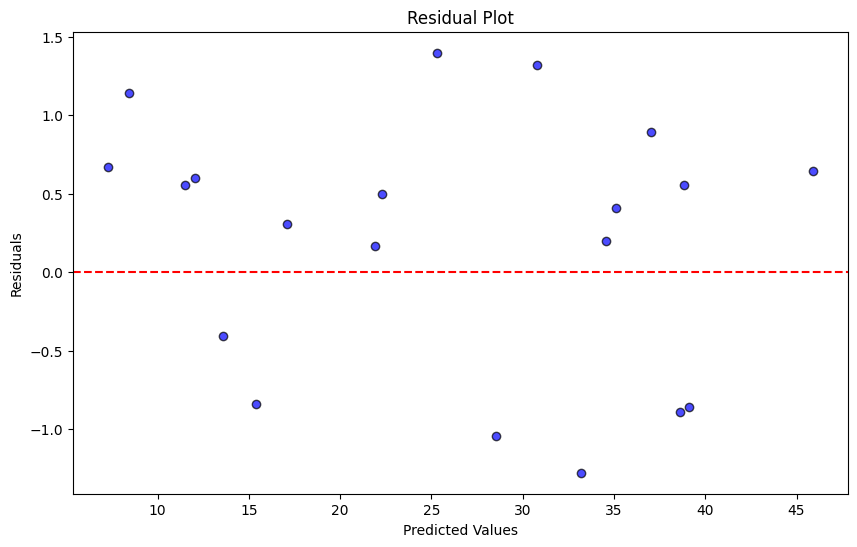

In [ ]:
import matplotlib.pyplot as plt

# Residuals (the difference between actual and predicted values)
residuals = y_test - y_pred

# Plot residuals
plt.figure(figsize=(10,6))
plt.scatter(y_pred, residuals, color='blue', edgecolor='black', alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residual Plot')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.show()


What to see here - If the residuals are randomly scattered around the horizontal line, it suggests the model's assumptions (linearity, homoscedasticity) hold true.

In [ ]:
# Another example

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('wine+quality/winequality-red.csv', delimiter=';')

# Display the first few rows
df.head()

# This dataset has the following features:
#     Fixed acidity
#     Volatile acidity
#     Citric acid
#     Residual sugar
#     Chlorides
#     Free sulfur dioxide
#     Total sulfur dioxide
#     Density
#     pH
#     Sulphates
#     Alcohol

# And the target variable is quality (which is an integer between 0 and 10 representing wine quality).

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
# Summary statistics for numerical features
print(df.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1599.000000       1599.000000  1599.000000     1599.000000   
mean        8.319637          0.527821     0.270976        2.538806   
std         1.741096          0.179060     0.194801        1.409928   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.390000     0.090000        1.900000   
50%         7.900000          0.520000     0.260000        2.200000   
75%         9.200000          0.640000     0.420000        2.600000   
max        15.900000          1.580000     1.000000       15.500000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  1599.000000          1599.000000           1599.000000  1599.000000   
mean      0.087467            15.874922             46.467792     0.996747   
std       0.047065            10.460157             32.895324     0.001887   
min       0.012000             1.000000         

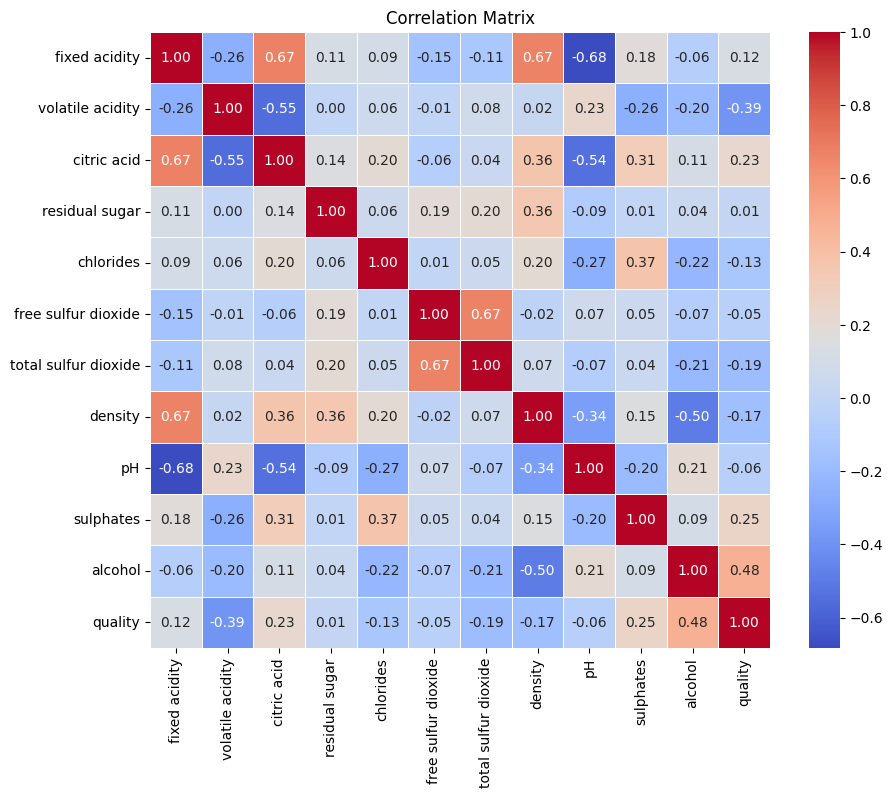

In [ ]:
# correlation matrix
import seaborn as sns

# Calculate the correlation matrix
corr_matrix = df.corr()

# Heatmap of the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


In [ ]:
# # just for your information ( this itself a seperate topic - feature selection)

# # Set a correlation threshold to filter out high correlations
# threshold = 0.6

# # Find pairs of features with high correlation
# high_corr = set()

# # Iterate over the correlation matrix
# for i in range(len(corr_matrix.columns)):
#     for j in range(i):
#         if abs(corr_matrix.iloc[i, j]) > threshold:
#             colname = corr_matrix.columns[i]
#             rowname = corr_matrix.columns[j]
#             high_corr.add((colname, rowname))

# # Print pairs of highly correlated features
# print("Highly Correlated Features:")
# for col1, col2 in high_corr:
#     print(f"{col1} and {col2}")


In [ ]:
# Check for missing values
print(df.isnull().sum())

# Split the dataset into features (X) and target (y)
X = df.drop('quality', axis=1)
y = df['quality']


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [ ]:
# Check for missing values
print(df.isnull().sum())

# Split the dataset into features (X) and target (y)
X = df.drop('quality', axis=1)
y = df['quality']


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')


Mean Squared Error: 0.3900251439639545
R-squared: 0.40318034127962254


R² indicates that about 40.32% of the variance in the target variable (y_test) is explained by the model.

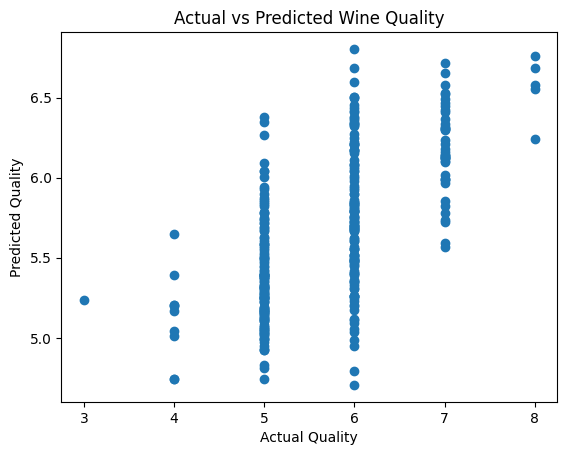

In [ ]:
import matplotlib.pyplot as plt

# Scatter plot for Actual vs Predicted
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Quality')
plt.ylabel('Predicted Quality')
plt.title('Actual vs Predicted Wine Quality')
plt.show()


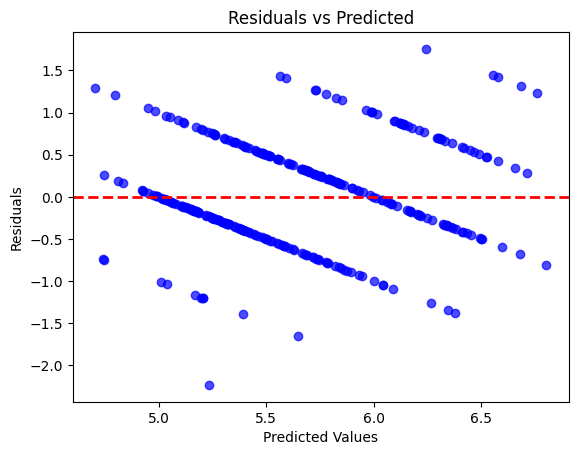

In [ ]:
# Calculate residuals
residuals = y_test - y_pred


plt.scatter(y_pred, residuals, color='blue', alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--', lw=2)
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

# print(residuals)
# Positive Residuals: These indicate that the predicted value is less than the actual value (i.e., under-predicted).
# Negative Residuals: These indicate that the predicted value is greater than the actual value (i.e., over-predicted).

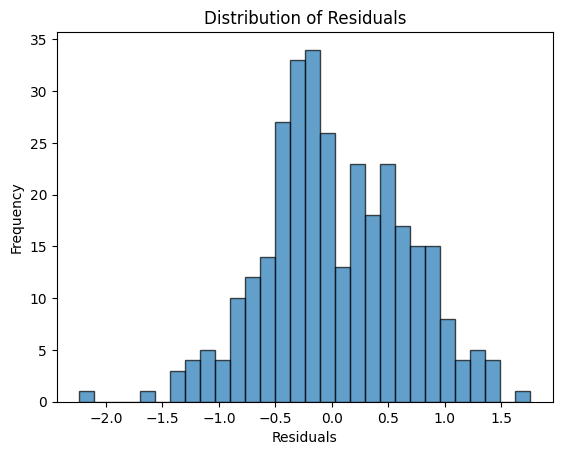

In [ ]:
plt.hist(residuals, bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')
plt.show()

In [ ]:
from sklearn.linear_model import Ridge

# Ridge regression with alpha (regularization strength)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

# Make predictions and evaluate
y_pred_ridge = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print(f'Mean Squared Error (Ridge): {mse_ridge}')
print(f'R-squared (Ridge): {r2_ridge}')


Mean Squared Error (Ridge): 0.39294886788127975
R-squared (Ridge): 0.39870643507758563


In [ ]:
from sklearn.linear_model import Lasso

# Lasso regression with alpha (regularization strength)
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

# Make predictions and evaluate
y_pred_lasso = lasso.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print(f'Mean Squared Error (Lasso): {mse_lasso}')
print(f'R-squared (Lasso): {r2_lasso}')


Mean Squared Error (Lasso): 0.49867516307447735
R-squared (Lasso): 0.23692319522368122


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Calculate RMSE
rmse_ridge = np.sqrt(mse_ridge)
rmse_lasso = np.sqrt(mse_lasso)


print(f'RMSE (Ridge): {rmse_ridge}')
print(f'RMSE (Lasso): {rmse_lasso}')


RMSE (Ridge): 0.6268563375138515
RMSE (Lasso): 0.7061693586346531


In [ ]:
# Please try

from sklearn.datasets import fetch_california_housing
import pandas as pd
data = fetch_california_housing()
X = data.data
y = data.target


In [ ]:
from sklearn.datasets import load_diabetes
import pandas as pd

# Load Diabetes dataset
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

In [ ]:
import pandas as pd



# Load Automobile dataset
url = 'Automobile_data.csv'
df = pd.read_csv(url)

# Preview dataset
print(df.head())

# keep the target as price



   symboling normalized-losses         make fuel-type aspiration num-of-doors  \
0          3                 ?  alfa-romero       gas        std          two   
1          3                 ?  alfa-romero       gas        std          two   
2          1                 ?  alfa-romero       gas        std          two   
3          2               164         audi       gas        std         four   
4          2               164         audi       gas        std         four   

    body-style drive-wheels engine-location  wheel-base  ...  engine-size  \
0  convertible          rwd           front        88.6  ...          130   
1  convertible          rwd           front        88.6  ...          130   
2    hatchback          rwd           front        94.5  ...          152   
3        sedan          fwd           front        99.8  ...          109   
4        sedan          4wd           front        99.4  ...          136   

   fuel-system  bore  stroke compression-ratio hor

In [ ]:
# StudentsPerformance.
url = 'StudentsPerformance.csv'
df = pd.read_csv(url)

# Preview dataset
print(df.head())

# keep the target as predict students' scores



   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
